# Day 7: Final House Price Models (Regression + Classification)

Final versions of Task 2 (predict the price) and Task 3 (predict expensive or not). Models and
settings were chosen on the validation set on Days 5 and 6. Here they are refit on
train + validation together and scored **once** on the test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, classification_report)

df = pd.read_csv("houses_clean.csv")
df = pd.get_dummies(df, columns=["location_zone"], drop_first=True, dtype=int)

train, temp = train_test_split(df, test_size=0.30, random_state=42)
val, test = train_test_split(temp, test_size=0.50, random_state=42)
trainval = pd.concat([train, val])

target = "price_million_pkr"
features = [c for c in df.columns if c != target]
print(f"train+val: {len(trainval)} rows | test: {len(test)} rows")

train+val: 252 rows | test: 45 rows


## Part A: Price prediction (regression)

In [2]:
reg = LinearRegression().fit(trainval[features], trainval[target])
pred = reg.predict(test[features])

mse = mean_squared_error(test[target], pred)
print(f"Test MAE : {mean_absolute_error(test[target], pred):.3f} million PKR")
print(f"Test RMSE: {mse ** 0.5:.3f} million PKR")
print(f"Test R2  : {r2_score(test[target], pred):.3f}")

Test MAE : 1.562 million PKR
Test RMSE: 1.846 million PKR
Test R2  : 0.878


In [3]:
# Coefficients in original units (easy to read) ...
coef = pd.Series(reg.coef_, index=features)

# ... and on standardized features (fair to compare, since every feature is on the same scale)
scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(trainval[features], trainval[target])
std_coef = pd.Series(scaled[-1].coef_, index=features)

print(pd.DataFrame({"coefficient": coef.round(3), "standardized": std_coef.round(3)}))

                         coefficient  standardized
area_marla                     0.902         4.356
bedrooms                       0.694         0.921
bathrooms                      0.481         0.607
age_years                     -0.070        -0.607
location_zone_Outskirts       -3.820        -1.747
location_zone_Suburban        -2.163        -1.068


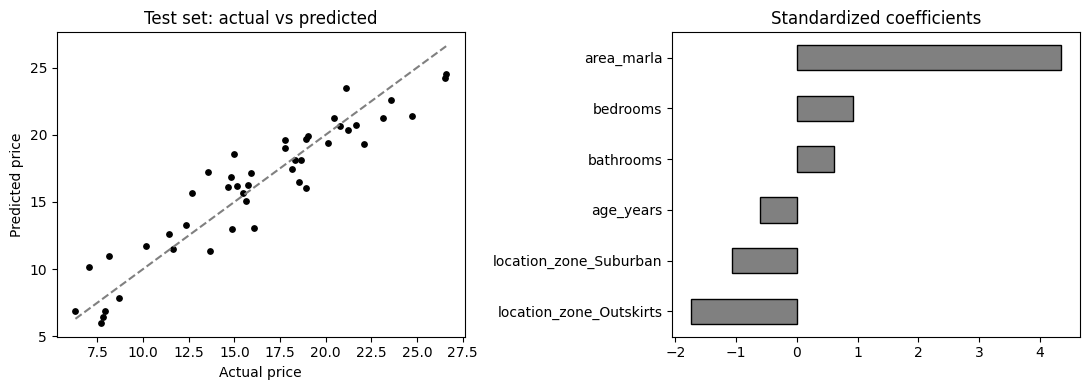

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(test[target], pred, color="black", s=15)
lims = [test[target].min(), test[target].max()]
axes[0].plot(lims, lims, color="grey", linestyle="--")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title("Test set: actual vs predicted")

std_coef.sort_values().plot.barh(ax=axes[1], color="grey", edgecolor="black")
axes[1].set_title("Standardized coefficients")
plt.tight_layout()
plt.show()

In [5]:
def predict_price(area_marla, bedrooms, bathrooms, age_years, zone="Central"):
    # returns the predicted price in million PKR. zone: Central, Suburban or Outskirts
    row = pd.DataFrame([{
        "area_marla": area_marla, "bedrooms": bedrooms, "bathrooms": bathrooms, "age_years": age_years,
        "location_zone_Outskirts": int(zone == "Outskirts"),
        "location_zone_Suburban": int(zone == "Suburban"),
    }])[features]
    return float(reg.predict(row)[0])

print("10 marla, 3 bed, 2 bath, 5 yrs, Suburban:", round(predict_price(10, 3, 2, 5, "Suburban"), 2))
print("10 marla, 3 bed, 2 bath, 5 yrs, Central :", round(predict_price(10, 3, 2, 5, "Central"), 2))

10 marla, 3 bed, 2 bath, 5 yrs, Suburban: 14.39
10 marla, 3 bed, 2 bath, 5 yrs, Central : 16.56


## Part B: Expensive or not (classification)

In [6]:
THRESHOLD = 15   # million PKR, same rule as Day 6
y_trainval = (trainval[target] > THRESHOLD).astype(int)
y_test = (test[target] > THRESHOLD).astype(int)

# hyperparameters picked on the validation set on Day 6
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=1)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
    "Decision Tree (depth=5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}
for m in models.values():
    m.fit(trainval[features], y_trainval)

test_acc = pd.Series({n: accuracy_score(y_test, m.predict(test[features])) for n, m in models.items()})
print(test_acc.round(3).sort_values(ascending=False))

Logistic Regression        0.867
KNN (k=1)                  0.867
Random Forest              0.867
Decision Tree (depth=5)    0.800
dtype: float64


In [7]:
forest = models["Random Forest"]
fpred = forest.predict(test[features])
print("Random Forest confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, fpred))
print()
print(classification_report(y_test, fpred, target_names=["not expensive", "expensive"]))

Random Forest confusion matrix (rows = actual, columns = predicted):
[[14  4]
 [ 2 25]]

               precision    recall  f1-score   support

not expensive       0.88      0.78      0.82        18
    expensive       0.86      0.93      0.89        27

     accuracy                           0.87        45
    macro avg       0.87      0.85      0.86        45
 weighted avg       0.87      0.87      0.87        45



### What drives the prediction?
Feature importance (random forest) says how much each feature helped, but not in which direction.
Logistic regression coefficients (on standardized features) give the direction as well.

Importances add up to: 1.0
                         RF importance  Logistic coef
area_marla                       0.483          3.083
bedrooms                         0.186          0.738
bathrooms                        0.168          0.783
age_years                        0.103         -0.296
location_zone_Outskirts          0.040         -1.162
location_zone_Suburban           0.020         -0.479


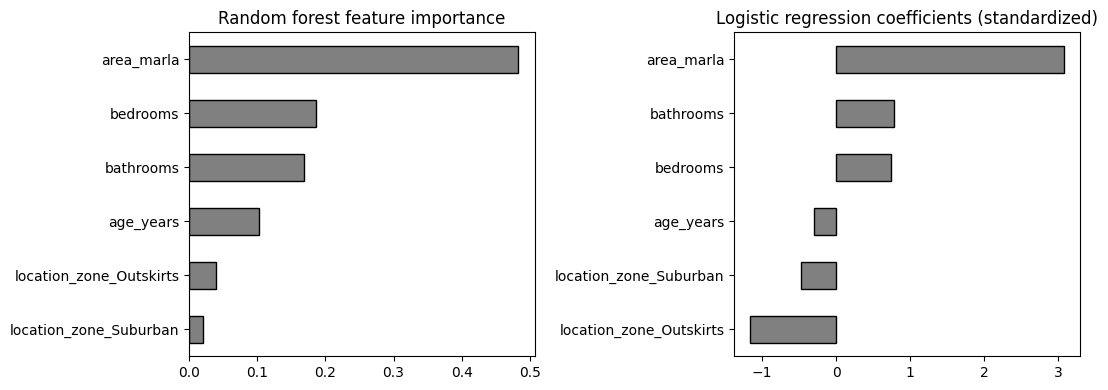

In [8]:
importance = pd.Series(forest.feature_importances_, index=features)
logit_coef = pd.Series(models["Logistic Regression"][-1].coef_[0], index=features)

print("Importances add up to:", round(importance.sum(), 3))
print(pd.DataFrame({"RF importance": importance.round(3), "Logistic coef": logit_coef.round(3)})
      .sort_values("RF importance", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
importance.sort_values().plot.barh(ax=axes[0], color="grey", edgecolor="black")
axes[0].set_title("Random forest feature importance")
logit_coef.sort_values().plot.barh(ax=axes[1], color="grey", edgecolor="black")
axes[1].set_title("Logistic regression coefficients (standardized)")
plt.tight_layout()
plt.show()

## Findings

**Regression.** On the test set the linear model gets R2 = 0.88 with an average error (MAE) of about
1.6 million PKR. Area is by far the strongest driver (largest standardized coefficient). Keeping
everything else equal, an Outskirts house is about 3.8 million cheaper than a Central one, and each
extra year of age lowers the price slightly.

**Classification.** Logistic Regression, KNN and Random Forest all reach 0.867 test accuracy, and the
Decision Tree gets 0.80. With only 45 test houses, one house is about 2%, so the first three are
effectively tied. The tree looked best on validation (0.933) and then dropped on test, a good reminder
that picking a model on a tiny validation set can be optimistic. In the random forest, area carries
almost half of the total importance (0.48).

**Limits.** The data is synthetic and small, so these numbers show the workflow, not real market
behaviour.